# The statistical baselines — what can simple generators already do?

Can a learned generator reproduce the variability of measured films?

This project's central question does not start with a neural network. It starts with two deliberately simple generators, fitted on training films only and judged on films they never saw.
1. The first does no learning at all. It draws training curves from a hat (bootstrap resampling with replacement) and can only ever copy. It shows how much fidelity a zero-effort strategy achieves for free, and it defines the novelty floor of exactly zero.
2. The second compresses the training cloud into its principal components and draws Gaussian coefficients along them: the strongest purely linear generator a population this low-dimensional admits.

Both, together with the evaluation code that judges them, were frozen before any learned model is tuned, so every later comparison stands against a fixed bar. The [audit report](../reports/data_audit.md) records the expectations set at that point.

This notebook presents the frozen baseline record. It re-runs the evaluation's code path with the same configuration and seeds, so the written record's numbers are verified rather than trusted. It then asks the question the figures raise on their own: where does the Gaussian assumption already fall short?

Terminology carries over from the [audit](audit.ipynb) and the [features notebook](features.ipynb). Curves are optical density `q = A/t` with thickness `t` in nm, values in nm⁻¹, on the 300–900 nm working span. All distances are Euclidean across the 301-wavelength grid, in the same units.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from absynth.baselines import bootstrap_resample, fit_pca_generator
from absynth.evaluation import (
    component_scores,
    covariance_record,
    mean_curve_deviation,
    memorization_record,
    nearest_training_distances,
    quantile_band,
)
from absynth.explore import nearest_neighbour_distances
from absynth.loader import load_dataset
from absynth.preprocessing import require_complete, restrict_to_span
from absynth.splits import date_block_holdout

CONFIG_PATH = Path("../configs/pilot.yaml")
RECORD_PATH = Path("../reports/pilot_baselines.json")
DATA_DIR = Path("../data/raw/Dataset")

## The held-out films

Every judgement below is made on films that the generators never saw. Which films may leave the training side is dictated by how the campaign was fabricated. Films coated on the same day share the precursor ink batch, the ambient conditions and the instrument state. They are correlated samples, so whole days move
as blocks. Within each substrate family, days are drawn for the held-out side separately, so both sides contain comparable optical contexts. Substrate stack moves these curves strongly. Stacks too small to support any held-out claim (at most 20 films in total) stay in training, and the held-out numbers describe the two common stacks only.

In [2]:
config = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8"))
dataset = load_dataset(DATA_DIR)
curves = restrict_to_span(dataset.curves)  # 300–900 nm; complete on this span
require_complete(curves)
wavelengths = curves.wavelengths_nm

split = date_block_holdout(
    dataset.parameters,
    test_fraction=float(config["split"]["test_fraction"]),
    seed=int(config["split"]["seed"]),
    rare_stack_max_films=int(config["split"]["rare_stack_max_films"]),
)
train = curves.optical_density[split.train_mask]
held_out = curves.optical_density[split.test_mask]

print(f"{curves.n_samples} films × {curves.n_wavelengths} wavelengths on the working span")
for side in ("train", "test"):
    summary = split.provenance[side]
    print(
        f"{side:>5}: {summary['n_films']} films, {summary['n_dates']} dates, "
        f"stacks {summary['stacks']}, thickness "
        f"{summary['thickness_nm']['min']}–{summary['thickness_nm']['max']} nm "
        f"(median {summary['thickness_nm']['median']})"
    )
print("rare stacks kept in training:", split.provenance["rare_stacks"])
print("held-out dates:", ", ".join(split.provenance["test"]["dates"]))

517 films × 301 wavelengths on the working span
train: 417 films, 17 dates, stacks {'glass': 254, 'corning': 150, 'glass / TiO2-c / TiO2-mp': 8, 'FTO / TiO2-c': 5}, thickness 107.5–1970.5 nm (median 440.0)
 test: 100 films, 3 dates, stacks {'glass': 59, 'corning': 41}, thickness 176.5–1299.5 nm (median 437.0)
rare stacks kept in training: ['FTO / TiO2-c', 'glass / TiO2-c / TiO2-mp']
held-out dates: 2023-10-04, 2024-02-28, 2024-11-12


The split lands close to its 20% target on both families, and the two sides look alike where they should. Comparable stack proportions, thickness medians within 3 nm of each other. Nothing makes the held-out days an easy or unusual subpopulation. Their internal diversity will confirm that below.

## Re-running the evaluation

The evaluation's entire recipe lives in one configuration file:
- The held-out fraction and its seed.
- The component count (99% of the working-span variance was found in four directions).
- How many curves each generator draws: as many as there are training films, so population-level metrics compare like-sized populations.
- A separate seed per draw.

All logic lives in the package. The script that wrote the frozen record only orchestrates. Running the same calls here with the same seeds should reproduce the record exactly, and this notebook checks rather than assumes.

In [3]:
n_samples = int(config["sampling"]["n_samples"])

floor = bootstrap_resample(
    train, n_samples, np.random.default_rng(int(config["sampling"]["floor_seed"]))
)
generator = fit_pca_generator(train, n_components=int(config["pca"]["n_components"]))
synthetic = generator.sample(n_samples, np.random.default_rng(int(config["sampling"]["seed"])))

print(f"PCA generator: {generator.n_components} components from {generator.n_training} films")
print(f"score scales (nm⁻¹): {np.round(generator.scales, 4)}")

PCA generator: 4 components from 417 films
score scales (nm⁻¹): [0.0491 0.0159 0.0076 0.0048]


**Distances:** for every generated curve, the distance to the nearest *training* curve. The same distances for held-out films — the scale of a genuinely new measurement — and, as a population-level reference, the nearest-neighbour median across all films.

In [4]:
floor_distances = nearest_training_distances(floor, train)
synthetic_distances = nearest_training_distances(synthetic, train)
heldout_distances = nearest_training_distances(held_out, train)
population_median = float(np.median(nearest_neighbour_distances(curves.optical_density)[0]))
print(f"nearest-neighbour median across all {curves.n_samples} films: {population_median:.4f} nm⁻¹")

nearest-neighbour median across all 517 films: 0.0049 nm⁻¹


Both baselines are evaluated with the frozen record's exact metrics: distribution, variability, memorization.
They are then compared against the record itself.

In [5]:
live = {
    "bootstrap_floor": {
        "memorization": memorization_record(floor_distances, heldout_distances),
        "mean_curve_deviation": mean_curve_deviation(train, floor),
    },
    "pca": {
        "memorization": memorization_record(synthetic_distances, heldout_distances),
        "mean_curve_deviation": mean_curve_deviation(train, synthetic),
        "covariance": covariance_record(train, synthetic),
    },
}
frozen = json.loads(RECORD_PATH.read_text(encoding="utf-8"))["baselines"]
mismatches = [
    f"{baseline}.{key}"
    for baseline, records in live.items()
    for key, values in records.items()
    if values != frozen[baseline][key]
]
if mismatches:
    print(f"MISMATCH against the frozen record: {mismatches}")
else:
    print("all live metrics match the frozen record exactly")

all live metrics match the frozen record exactly


## Fidelity: does the population look like films?

Fidelity asks whether a generated population could pass for measured films, and it is read on two levels:

Do average curves and quantile bands coincide, and does the variability structure — which wavelengths move together, and by how much — carry over?
The variability comparison is a relative distance: 0 means identical second-order structure, 1 means the difference is as large as the measured variability itself.

One calibration before reading the table: the floor *replays* real curves, so its mean curve sits at mere resampling noise from the measured one. Fidelity at this level is free. Matching it is necessary, never sufficient.

In [6]:
scoreboard = pd.DataFrame(
    {
        "bootstrap floor": {
            "mean-curve deviation, max (nm⁻¹)": live["bootstrap_floor"]["mean_curve_deviation"]["max_abs"],
            "mean-curve deviation, mean (nm⁻¹)": live["bootstrap_floor"]["mean_curve_deviation"]["mean_abs"],
            "covariance distance (relative)": np.nan,
            "correlation distance (relative)": np.nan,
            "novelty: median-distance ratio": live["bootstrap_floor"]["memorization"]["median_ratio"],
        },
        "PCA Gaussian": {
            "mean-curve deviation, max (nm⁻¹)": live["pca"]["mean_curve_deviation"]["max_abs"],
            "mean-curve deviation, mean (nm⁻¹)": live["pca"]["mean_curve_deviation"]["mean_abs"],
            "covariance distance (relative)": live["pca"]["covariance"]["covariance_relative_frobenius"],
            "correlation distance (relative)": live["pca"]["covariance"]["correlation_relative_frobenius"],
            "novelty: median-distance ratio": live["pca"]["memorization"]["median_ratio"],
        },
    }
)
scoreboard.round(4)

,bootstrap floor,PCA Gaussian
"mean-curve deviation, max (nm⁻¹)",0.0005,0.0004
"mean-curve deviation, mean (nm⁻¹)",0.0001,0.0001
covariance distance (relative),NaN,0.0616
correlation distance (relative),NaN,0.0418
novelty: median-distance ratio,0.0000,1.6471


The covariance rows are tracked for the PCA generator only: the floor's variability structure is the training set's up to resampling noise, so that comparison carries no information about it.

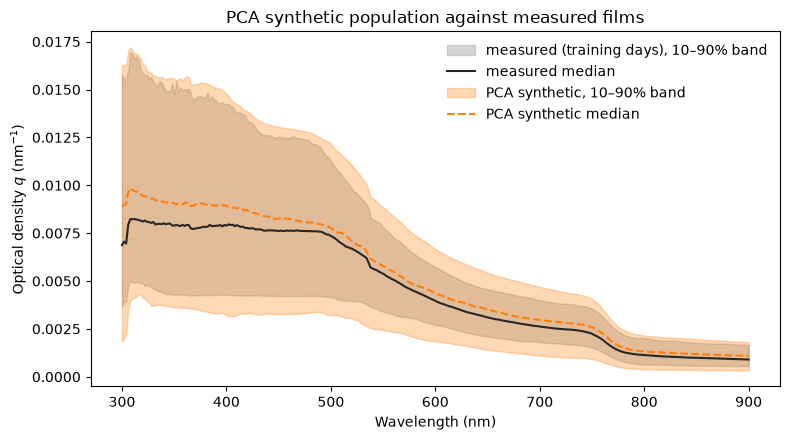

In [7]:
band_real = quantile_band(train, quantiles=(0.1, 0.5, 0.9))
band_synthetic = quantile_band(synthetic, quantiles=(0.1, 0.5, 0.9))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(
    wavelengths, band_real[0], band_real[2], color="0.55", alpha=0.35,
    label="measured (training days), 10–90% band",
)
ax.plot(wavelengths, band_real[1], color="0.15", label="measured median")
ax.fill_between(
    wavelengths, band_synthetic[0], band_synthetic[2], color="tab:orange",
    alpha=0.30, label="PCA synthetic, 10–90% band",
)
ax.plot(wavelengths, band_synthetic[1], "--", color="tab:orange", label="PCA synthetic median")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel(r"Optical density $q$ (nm$^{-1}$)")
ax.set_title("PCA synthetic population against measured films")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

The PCA generator's variability structure carries over: a covariance distance of 6.2% and a correlation distance of 4.2%.
The generated population varies the way films vary, which is what drawing independent Gaussians with the measured per-direction spreads promises.
Against plateau curve heights of order 10⁻² nm⁻¹ (the features notebook's scale), the mean-curve deviations are percent-level. But look closely at the plateau in the bands. The synthetic median rides consistently *above* the measured median there, while the two populations' means agree to 6×10⁻⁵ nm⁻¹.
A population can match in mean and covariance and still differ in shape. The last section returns to this point in the generator's own coordinates.

## Novelty: is it new, or copied?

Fidelity says nothing about whether a model creates or replays. The memorization comparison plots each population's nearest-training-curve distances as cumulative profiles, with two anchors: the floor, exactly zero by construction, and held-out films, the distance profile of genuinely new measurements.
The summary ratio — synthetic median over held-out median — reads near 0 as copying, near 1 as novel at the population's own diversity scale, well above 1 as overshooting into regions real films barely reach.

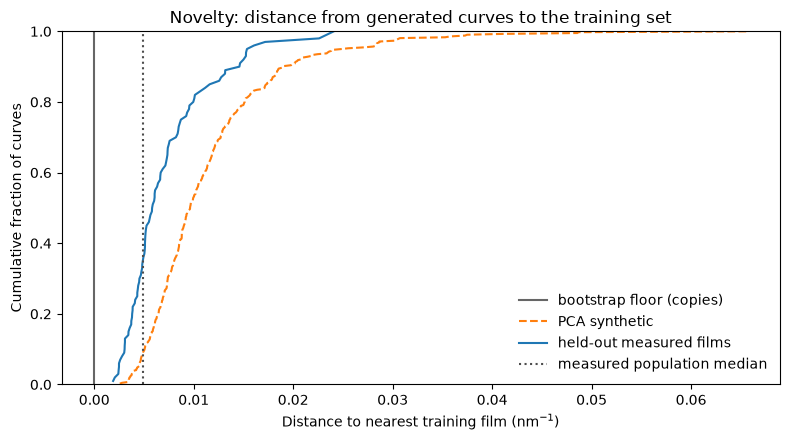

medians (nm⁻¹): floor 0.0000, PCA 0.0096, held-out 0.0058


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
profiles = (
    (floor_distances, "bootstrap floor (copies)", "0.4", "-"),
    (synthetic_distances, "PCA synthetic", "tab:orange", "--"),
    (heldout_distances, "held-out measured films", "tab:blue", "-"),
)
for values, label, color, style in profiles:
    ordered = np.sort(values)
    ax.plot(
        ordered, np.arange(1, ordered.size + 1) / ordered.size,
        label=label, color=color, linestyle=style,
    )
ax.axvline(population_median, color="0.3", linestyle=":", label="measured population median")
ax.set_xlabel(r"Distance to nearest training film (nm$^{-1}$)")
ax.set_ylabel("Cumulative fraction of curves")
ax.set_ylim(0, 1)
ax.set_title("Novelty: distance from generated curves to the training set")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

print(
    f"medians (nm⁻¹): floor {np.median(floor_distances):.4f}, "
    f"PCA {np.median(synthetic_distances):.4f}, held-out {np.median(heldout_distances):.4f}"
)

The profiles separate cleanly. The floor's collapses onto zero. A copy has no novelty. Held-out films centre on 5.8×10⁻³ nm⁻¹ (10–90% band 3.1–14.6×10⁻³), close to the population-wide median of 4.9×10⁻³. The held-out days are ordinary films, neither an easy nor a pathological subset. The PCA generator's curves sit farther out: median 9.6×10⁻³, a ratio of 1.65.

The profile's left edge lies well away from zero. Nothing is copied, so the linear generator genuinely composes new combinations of its four variability directions. But overshooting the held-out scale by ~65% says the Gaussian draws also wander into outskirts the measured cloud leaves empty: combinations of large, independent coefficients that no real film visits. Novelty is not free of charge. It has to be the *right* novelty.

## Where the Gaussian assumption already falls short

The generator draws each component's coefficient from an independent Gaussian with that direction's measured spread. That construction reproduces means and spreads by design, however it promises nothing about *shape* beyond them. The plateau gap above is exactly where the promise runs out. The amplitude axis explains it. Component 1 is amplitude (the [features notebook](features.ipynb) found it tracking the integrated windows at r ≈ 0.98), and the measured distribution of
amplitude scores over training films is right-skewed: most films absorb moderately, a tail of strong absorbers pulls the mean upward.
A Gaussian places its median at its mean. The synthetic population's typical film therefore absorbs more than the measured typical film. Means match, medians do not, and on the plateau, where amplitude sets the curve height, the median gap is the visible trace of the skewness.

In [9]:
mean_gap = np.abs(synthetic.mean(axis=0) - train.mean(axis=0))
median_gap = np.abs(np.median(synthetic, axis=0) - np.median(train, axis=0))
plateau = (wavelengths >= 300) & (wavelengths <= 500)
print(f"mean curves:   max gap {mean_gap.max():.2e} nm⁻¹, mean gap {mean_gap.mean():.2e} nm⁻¹")
print(
    f"median curves: max gap {median_gap.max():.2e} nm⁻¹ near "
    f"{wavelengths[median_gap.argmax()]:.0f} nm"
)
print(f"median gap averaged over the 300–500 nm plateau: {median_gap[plateau].mean():.2e} nm⁻¹")

mean curves:   max gap 4.31e-04 nm⁻¹, mean gap 5.96e-05 nm⁻¹
median curves: max gap 2.07e-03 nm⁻¹ near 304 nm
median gap averaged over the 300–500 nm plateau: 9.61e-04 nm⁻¹


Same populations, same grid: the mean-based summary stays at the 10⁻⁵–10⁻⁴ level while the median-based summary peaks at 2.1×10⁻³ nm⁻¹ near 304 nm, against the mean summary's 4.3×10⁻⁴ maximum — a contrast the mean alone cannot tell. The scores show why. Component scores place every training film in the exact coordinates the generator draws in. If the Gaussian assumption held, each score column would look symmetric around zero.

In [10]:
scores = component_scores(train, generator.mean, generator.components)
skewness = pd.DataFrame(
    scores, columns=[f"component {i + 1}" for i in range(scores.shape[1])]
).skew()
skewness.round(3)

component 1    2.297
component 2    0.705
component 3   -0.679
component 4    0.657
dtype: float64

Component 1's skewness is 2.3, strongly right-skewed. The remaining components are moderately skewed too (0.7, −0.7, 0.7). No score column is symmetric, and amplitude is the extreme case. The histogram makes the mismatch direct for the amplitude axis. The measured scores pile up below their mean with a tail to the right. In contrast the fitted Gaussian spreads symmetrically, putting half its draws above the mean, whereas the measured population puts fewer.

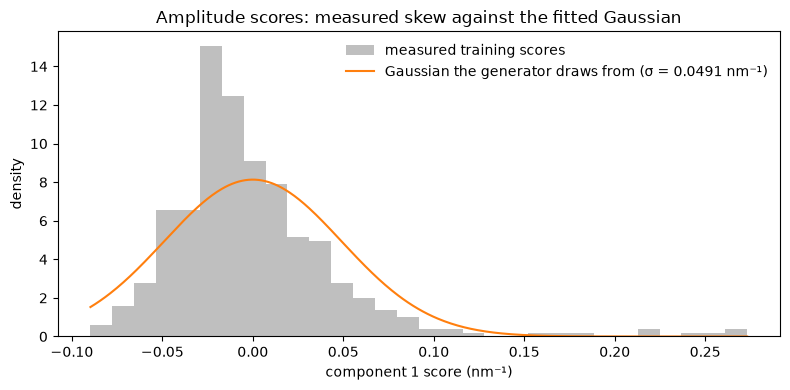

In [11]:
axis = 0  # component 1: amplitude
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores[:, axis], bins=30, density=True, color="0.75", label="measured training scores")
grid = np.linspace(scores[:, axis].min(), scores[:, axis].max(), 400)
gaussian = np.exp(-0.5 * (grid / generator.scales[axis]) ** 2) / (
    generator.scales[axis] * np.sqrt(2 * np.pi)
)
ax.plot(
    grid, gaussian, color="tab:orange",
    label=f"Gaussian the generator draws from (σ = {generator.scales[axis]:.4f} nm⁻¹)",
)
ax.set_xlabel("component 1 score (nm⁻¹)")
ax.set_ylabel("density")
ax.set_title("Amplitude scores: measured skew against the fitted Gaussian")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Two consequences now define what a neural model must achieve.
1. The bar is now concrete. A learned generator must hold this fidelity — percent-level mean deviations, variability distances of the same order — while pulling the novelty ratio from 1.65 toward the held-out anchor at 1: curves as close to the training set as genuinely new films, not farther, and not closer. And it must repair the shape the Gaussian cannot: skewed amplitude first, whatever the other score histograms show next.
2. The audit report's pre-registered expectation stands unchanged: on a population with 99% of its variance in four directions, matching the PCA generator is a valid outcome, and a neural model earns its complexity only through measurable advantage — in the tails this notebook has started to expose, in covariance structure beyond four directions, or in conditional behaviour. If it cannot beat four Gaussians where it counts, then *"it is what it is"*.

## Findings

1. **The frozen evaluation reproduces.** Re-running its code path here — same configuration file, same seeds, same data checksum — matches `reports/pilot_baselines.json` to the last bit. The record demands no trust, only a rerun.
2. **Fidelity is nearly free; novelty is what discriminates.** Even the copying floor matches measured mean curves to percent level (max deviation 5×10⁻⁴ nm⁻¹) with zero novelty. "Looks real" cannot be the goal; novelty at held fidelity is.
3. **The PCA generator is genuinely novel — and overshoots.** Nothing is copied (the profile's left edge is far from zero), yet its curves sit ~65% farther from the training set than genuinely new films (median ratio 1.65). Gaussian tails populate coefficient combinations real films never visit.
4. **Variability structure carries over.** Covariance distance 6.2%, correlation distance 4.2%: the generated population varies the way films vary, as the construction promises.
5. **The first measurable Gaussian miss is amplitude skewness.** Means agree to 6×10⁻⁵ nm⁻¹ while the synthetic median rides above the measured median on the plateau (max median gap 2.1×10⁻³ nm⁻¹ near 304 nm; component-1 score skewness 2.3). The next question is whether a small VAE repairs the shape, or whether the honest result is that four Gaussians were enough.
